### GAMMAFEST 2026
### Tim: **Bumbu Ireng Pak Jenggot**

### Import Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.figsize'] = (14, 5)

train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
print(f"Train shape: {train.shape}  |  Test shape: {test.shape}")
train.head(3)


Train shape: (78772, 47)  |  Test shape: (42422, 20)


,Id,match_id,date,gender,team,opponent,is_home,neutral,tournament,venue_country,...,confederation_team,confederation_opp,population_team,population_opp,gdp_per_capita_team,gdp_per_capita_opp,altitude_venue,distance_travel_team,distance_travel_opp,temperature_venue
0,M000001_Scotland,M000001,1872-11-30,M,Scotland,England,1,0,Friendly,Scotland,...,UEFA,UEFA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,M000001_England,M000001,1872-11-30,M,England,Scotland,0,0,Friendly,Scotland,...,UEFA,UEFA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,M000002_England,M000002,1873-03-08,M,England,Scotland,1,0,Friendly,England,...,UEFA,UEFA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Exploratory Data Analysis (EDA)

### Data Preprocessing (Historical Only)

In [2]:
# 1. Data Sorting & Alignment
print("1. Sorting and basic feature extraction...")
train['date'] = pd.to_datetime(train['date'])
train = train.sort_values('date')
train['year'] = train['date'].dt.year
train['month'] = train['date'].dt.month
train['day_of_week'] = train['date'].dt.dayofweek

# 2. Handling Missing Values & Sentinels
print("2. Handling altitude sentinel...")
train['altitude_venue'] = train['altitude_venue'].replace(-9999, np.nan)
train = train.sort_values(['date', 'match_id', 'team']).reset_index(drop=True)

# Intermediate columns for rolling calculation
train['outcome_points'] = np.where(train['team_goals'] > train['opp_goals'], 3,
                                  np.where(train['team_goals'] == train['opp_goals'], 1, 0))
train['outcome_gd'] = train['team_goals'] - train['opp_goals']

# 3. Performance Metrics (Last 5 & Last 10)
print("3. Calculating rolling performance metrics...")
group_cols = ['team', 'gender']
train['team_points_last5'] = train.groupby(group_cols)['outcome_points'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
train['team_points_last10'] = train.groupby(group_cols)['outcome_points'].transform(lambda x: x.shift(1).rolling(10, min_periods=1).sum())
train['team_gd_last5'] = train.groupby(group_cols)['outcome_gd'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
train['team_win_rate_last10'] = train.groupby(group_cols)['outcome_points'].transform(lambda x: x.shift(1).rolling(10, min_periods=1).apply(lambda y: (y == 3).mean() if len(y)>0 else np.nan, raw=True))
train['team_avg_goals_last5'] = train.groupby(group_cols)['team_goals'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
train['team_avg_conceded_last5'] = train.groupby(group_cols)['opp_goals'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
train['days_since_last_match_team'] = train.groupby(group_cols)['date'].diff().dt.days

# 4. H2H Metrics
print("4. Calculating H2H metrics...")
train['h2h_points_last5'] = train.groupby(['team', 'opponent', 'gender'])['outcome_points'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
train['h2h_gd_last5'] = train.groupby(['team', 'opponent', 'gender'])['outcome_gd'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())

# 5. Synchronize opp_ features
print("5. Synchronizing opponent features...")
sync_map = {
    'team_points_last5': 'opp_points_last5',
    'team_points_last10': 'opp_points_last10',
    'team_gd_last5': 'opp_gd_last5',
    'team_win_rate_last10': 'opp_win_rate_last10',
    'team_avg_goals_last5': 'opp_avg_goals_last5',
    'team_avg_conceded_last5': 'opp_avg_conceded_last5',
    'days_since_last_match_team': 'days_since_last_match_opp'
}
mirror_df = train[['match_id', 'team'] + list(sync_map.keys())].copy()
mirror_df.columns = ['match_id', 'opponent'] + list(sync_map.values())
train = train.drop(columns=[v for v in sync_map.values() if v in train.columns])
train = train.merge(mirror_df, on=['match_id', 'opponent'], how='left')

# 6. Geographic & Socio-economic Data (Internal Imputation)
print("6. Imputing geographic and socio-economic data...")
train['population_team'] = train.groupby('team')['population_team'].ffill()
train['gdp_per_capita_team'] = train.groupby('team')['gdp_per_capita_team'].ffill()
train['altitude_venue'] = train.groupby('venue_country')['altitude_venue'].ffill()
train['temperature_venue'] = train.groupby('venue_country')['temperature_venue'].ffill()
train['distance_travel_team'] = train.groupby('team')['distance_travel_team'].ffill()

geo_map = {'population_team': 'population_opp', 'gdp_per_capita_team': 'gdp_per_capita_opp', 'distance_travel_team': 'distance_travel_opp'}
mirror_geo = train[['match_id', 'team'] + list(geo_map.keys())].copy()
mirror_geo.columns = ['match_id', 'opponent'] + list(geo_map.values())
train = train.drop(columns=[v for v in geo_map.values() if v in train.columns])
train = train.merge(mirror_geo, on=['match_id', 'opponent'], how='left')

# 7. Final Cleanup & Requirements
print("7. Dropping rank columns and filling remaining NaNs...")
drop_cols = ['rank_team', 'rank_opponent', 'rank_diff', 'rank_missing_team', 'rank_missing_opp']
train.drop(columns=[col for col in drop_cols if col in train.columns], inplace=True)

fill_zero_cols = list(sync_map.keys()) + list(sync_map.values()) + ['h2h_points_last5', 'h2h_gd_last5', 'team_points_last10', 'opp_points_last10', 'team_win_rate_last10', 'opp_win_rate_last10']
for col in fill_zero_cols:
    if col in train.columns:
        train[col] = train[col].fillna(0)

if 'days_since_last_match_team' in train.columns:
    train['days_since_last_match_team'] = train['days_since_last_match_team'].fillna(9999)
if 'days_since_last_match_opp' in train.columns:
    train['days_since_last_match_opp'] = train['days_since_last_match_opp'].fillna(9999)

train['points_last5_diff'] = train['team_points_last5'] - train['opp_points_last5']
train['gd_last5_diff'] = train['team_gd_last5'] - train['opp_gd_last5']

train.drop(columns=['outcome_points', 'outcome_gd'], inplace=True)

1. Sorting and basic feature extraction...
2. Handling altitude sentinel...
3. Calculating rolling performance metrics...
4. Calculating H2H metrics...
5. Synchronizing opponent features...
6. Imputing geographic and socio-economic data...
7. Dropping rank columns and filling remaining NaNs...


### Basic Info & Missing Values


In [3]:
train.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78772 entries, 0 to 78771
Data columns (total 45 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Id                          78772 non-null  object        
 1   match_id                    78772 non-null  object        
 2   date                        78772 non-null  datetime64[ns]
 3   gender                      78772 non-null  object        
 4   team                        78772 non-null  object        
 5   opponent                    78772 non-null  object        
 6   is_home                     78772 non-null  int64         
 7   neutral                     78772 non-null  int64         
 8   tournament                  78772 non-null  object        
 9   venue_country               78772 non-null  object        
 10  team_goals                  78772 non-null  int64         
 11  opp_goals                   78772 non-null  int64     

In [4]:
# Missing value percentages
miss = train.isnull().mean().mul(100).round(2)
miss_test = test.isnull().mean().mul(100).round(2)

# Gunakan backtick (`) untuk membungkus nama kolom
miss_df = pd.DataFrame({'train_%': miss, 'test_%': miss_test}) \
            .query('`train_%` > 0 or `test_%` > 0') \
            .sort_values('train_%', ascending=False)
            
display(miss_df.style.background_gradient(cmap='Reds'))



,train_%,test_%
gdp_per_capita_opp,32.730000,34.570000
gdp_per_capita_team,32.730000,34.570000
distance_travel_opp,28.190000,40.010000
distance_travel_team,28.190000,40.010000
altitude_venue,27.070000,25.710000
temperature_venue,21.680000,13.190000
population_opp,18.880000,7.950000
population_team,18.880000,7.950000


## Target Distribution


team_goals => mean=1.56, median=1.0, max=31
opp_goals => mean=1.56, median=1.0, max=31


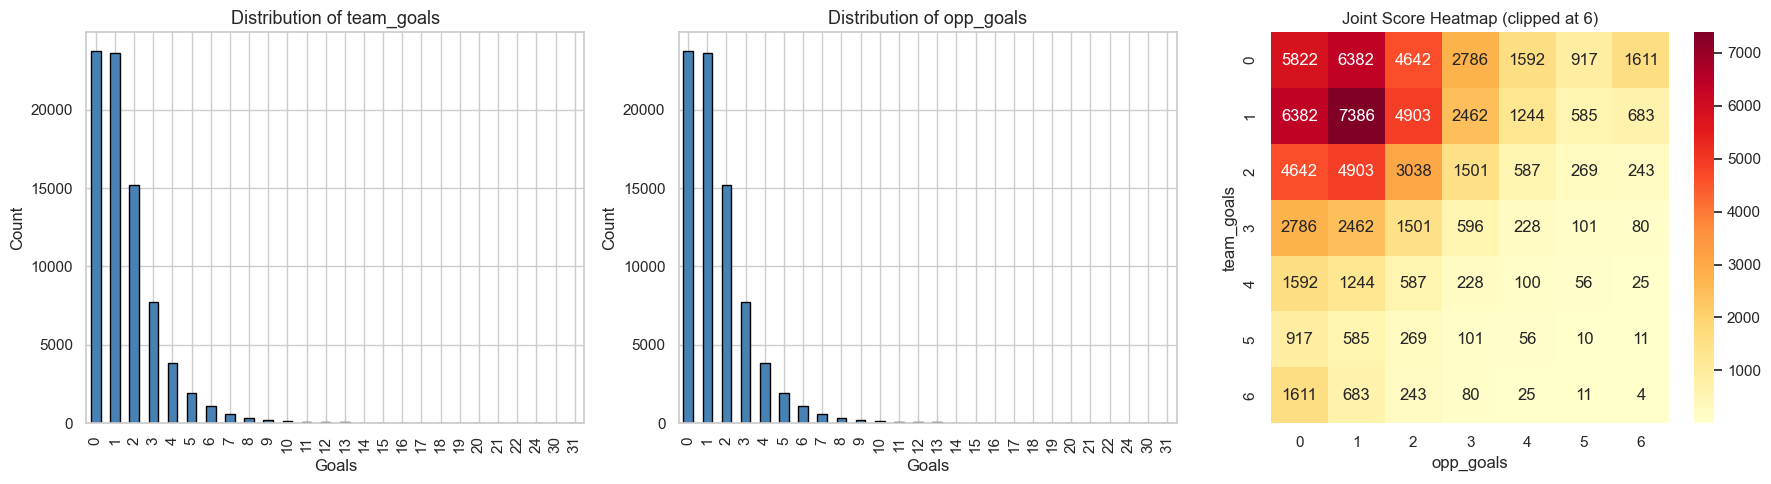

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes[:2], ['team_goals', 'opp_goals']):
    train[col].value_counts().sort_index().plot.bar(ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(f'Distribution of {col}', fontsize=13)
    ax.set_xlabel('Goals'); ax.set_ylabel('Count')
    print(f"{col} => mean={train[col].mean():.2f}, median={train[col].median()}, max={train[col].max()}")

# Joint distribution
ct = pd.crosstab(train['team_goals'].clip(upper=6), train['opp_goals'].clip(upper=6))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd', ax=axes[2])
axes[2].set_title('Joint Score Heatmap (clipped at 6)')
plt.tight_layout(); plt.show()


## Categorical Features


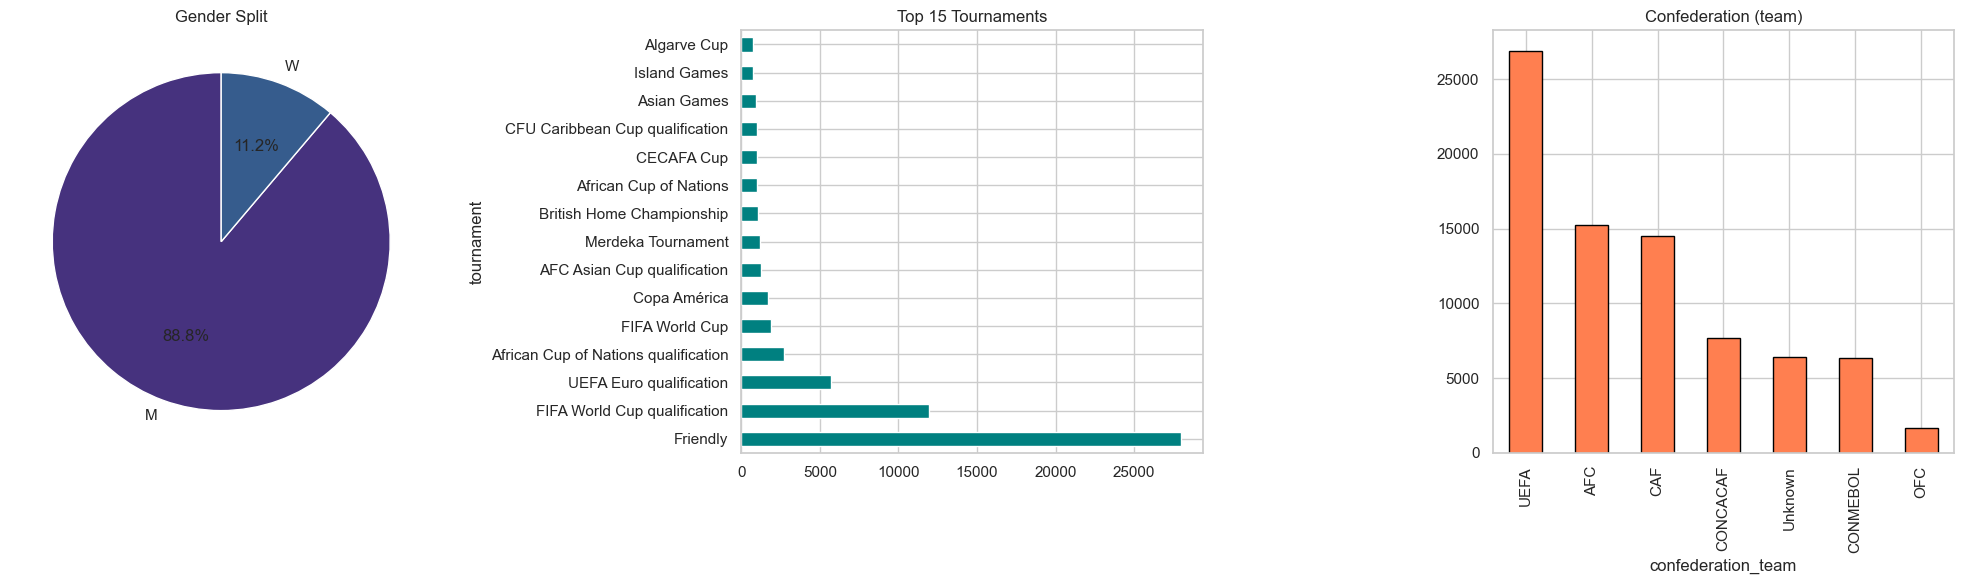

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

train['gender'].value_counts().plot.pie(ax=axes[0], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Gender Split')
axes[0].set_ylabel('')

train['tournament'].value_counts().head(15).plot.barh(ax=axes[1], color='teal')
axes[1].set_title('Top 15 Tournaments')

train['confederation_team'].value_counts().plot.bar(ax=axes[2], color='coral', edgecolor='black')
axes[2].set_title('Confederation (team)')
plt.tight_layout(); plt.show()


In [7]:
# Home advantage
home = train.groupby('is_home')[['team_goals','opp_goals']].mean()
home['goal_diff'] = home['team_goals'] - home['opp_goals']
display(home.round(3))

# Neutral venue
neutral = train.groupby('neutral')[['team_goals','opp_goals']].mean()
display(neutral.round(3))


,team_goals,opp_goals,goal_diff
is_home,,,
0,1.238,1.889,-0.651
1,1.889,1.238,0.651


,team_goals,opp_goals
neutral,,
0,1.528,1.528
1,1.658,1.658


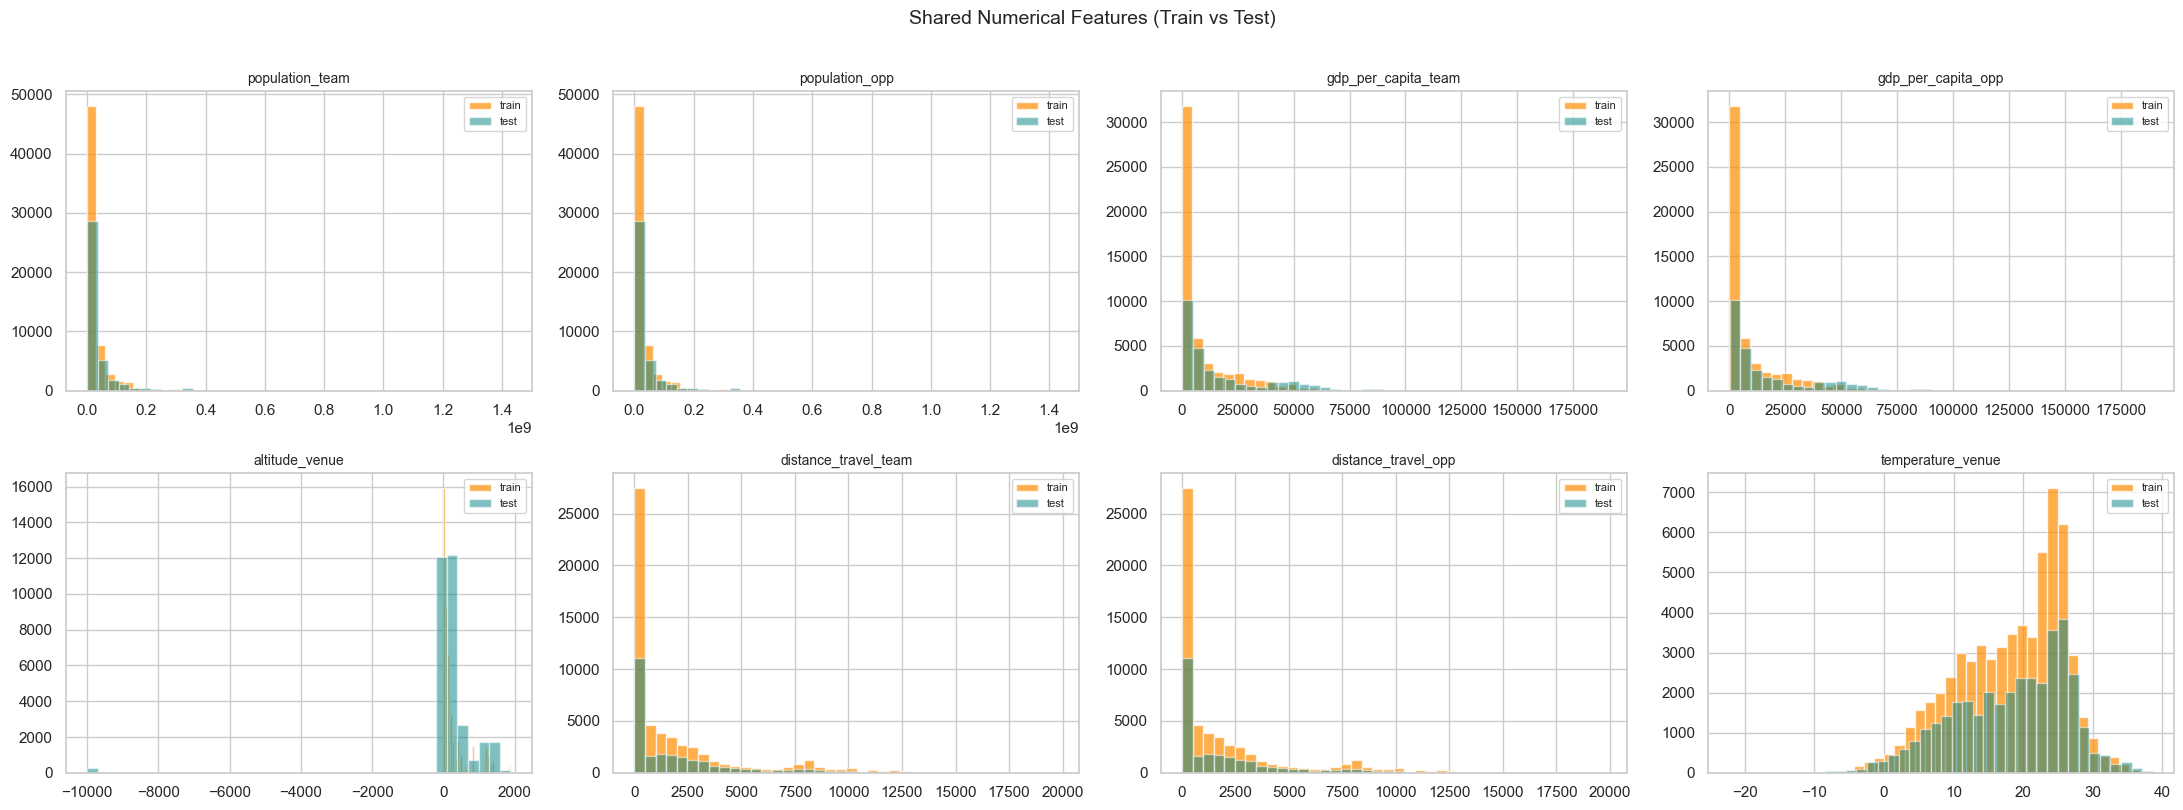

In [8]:
shared_num = ['population_team','population_opp','gdp_per_capita_team','gdp_per_capita_opp',
              'altitude_venue','distance_travel_team','distance_travel_opp','temperature_venue']

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for ax, col in zip(axes.flat, shared_num):
    train[col].dropna().hist(bins=40, ax=ax, color='darkorange', edgecolor='white', alpha=0.7, label='train')
    test[col].dropna().hist(bins=40, ax=ax, color='teal', edgecolor='white', alpha=0.5, label='test')
    ax.set_title(col, fontsize=10); ax.legend(fontsize=8)
plt.suptitle('Shared Numerical Features (Train vs Test)', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()


## 1. Univariate Analysis

### 1.1 Numerical Variables
Mengecek statistik 5 serangkai (Min, Q1, Median, Q3, Max), sebaran, dan identifikasi outlier.


In [9]:
num_cols = train.select_dtypes(include=['number']).columns.tolist()
print(f"Numerical Columns: {num_cols}")

# Statistik 5 Serangkai + Mean & Std
display(train[num_cols].describe().T)

# Cek missing values
missing_num = train[num_cols].isnull().sum()
print("\nMissing Values in Numerical Columns:")
print(missing_num[missing_num > 0])

Numerical Columns: ['is_home', 'neutral', 'team_goals', 'opp_goals', 'team_points_last5', 'points_last5_diff', 'team_gd_last5', 'gd_last5_diff', 'h2h_points_last5', 'h2h_gd_last5', 'days_since_last_match_team', 'team_points_last10', 'team_avg_goals_last5', 'team_avg_conceded_last5', 'team_win_rate_last10', 'elo_team', 'elo_opponent', 'population_team', 'gdp_per_capita_team', 'altitude_venue', 'distance_travel_team', 'temperature_venue', 'year', 'month', 'day_of_week', 'opp_points_last5', 'opp_points_last10', 'opp_gd_last5', 'opp_win_rate_last10', 'opp_avg_goals_last5', 'opp_avg_conceded_last5', 'days_since_last_match_opp', 'population_opp', 'gdp_per_capita_opp', 'distance_travel_opp']


,count,mean,std,min,25%,50%,75%,max
is_home,78772.0,5.000000e-01,5.000032e-01,0.000000,0.000000e+00,5.000000e-01,1.000000e+00,1.000000e+00
neutral,78772.0,2.690296e-01,4.434582e-01,0.000000,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
team_goals,78772.0,1.563119e+00,1.792137e+00,0.000000,0.000000e+00,1.000000e+00,2.000000e+00,3.100000e+01
opp_goals,78772.0,1.563119e+00,1.792137e+00,0.000000,0.000000e+00,1.000000e+00,2.000000e+00,3.100000e+01
team_points_last5,78772.0,6.862438e+00,3.701088e+00,0.000000,4.000000e+00,7.000000e+00,1.000000e+01,1.500000e+01
points_last5_diff,78772.0,0.000000e+00,4.988726e+00,-15.000000,-3.000000e+00,0.000000e+00,3.000000e+00,1.500000e+01
team_gd_last5,78772.0,8.657899e-02,8.113338e+00,-68.000000,-4.000000e+00,0.000000e+00,4.000000e+00,6.800000e+01
gd_last5_diff,78772.0,0.000000e+00,1.086499e+01,-89.000000,-6.000000e+00,0.000000e+00,6.000000e+00,8.900000e+01
h2h_points_last5,78772.0,4.315544e+00,4.193821e+00,0.000000,0.000000e+00,3.000000e+00,7.000000e+00,1.500000e+01
h2h_gd_last5,78772.0,0.000000e+00,6.359813e+00,-54.000000,-2.000000e+00,0.000000e+00,2.000000e+00,5.400000e+01



Missing Values in Numerical Columns:
population_team         14872
gdp_per_capita_team     25785
altitude_venue          21320
distance_travel_team    22205
temperature_venue       17074
population_opp          14872
gdp_per_capita_opp      25785
distance_travel_opp     22205
dtype: int64


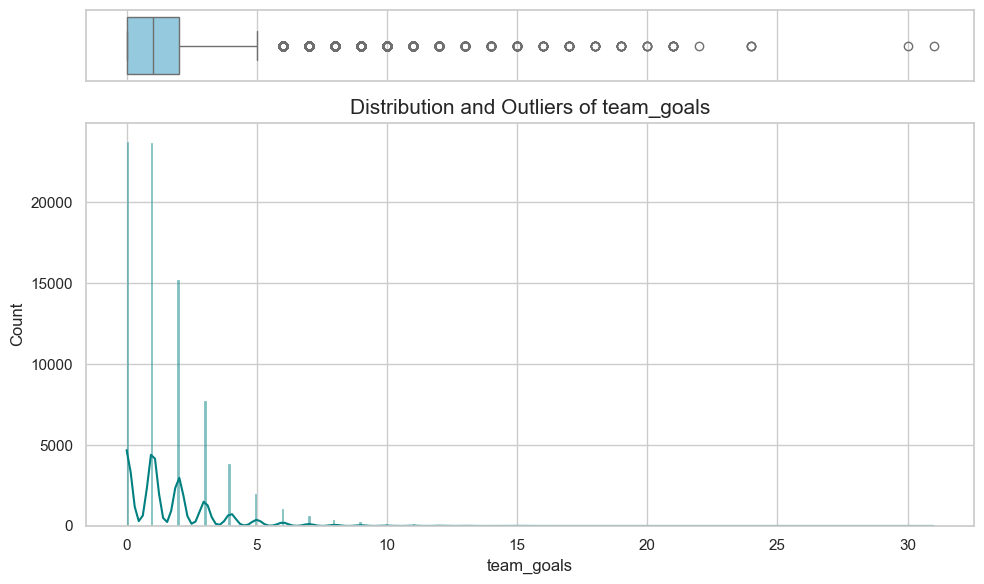

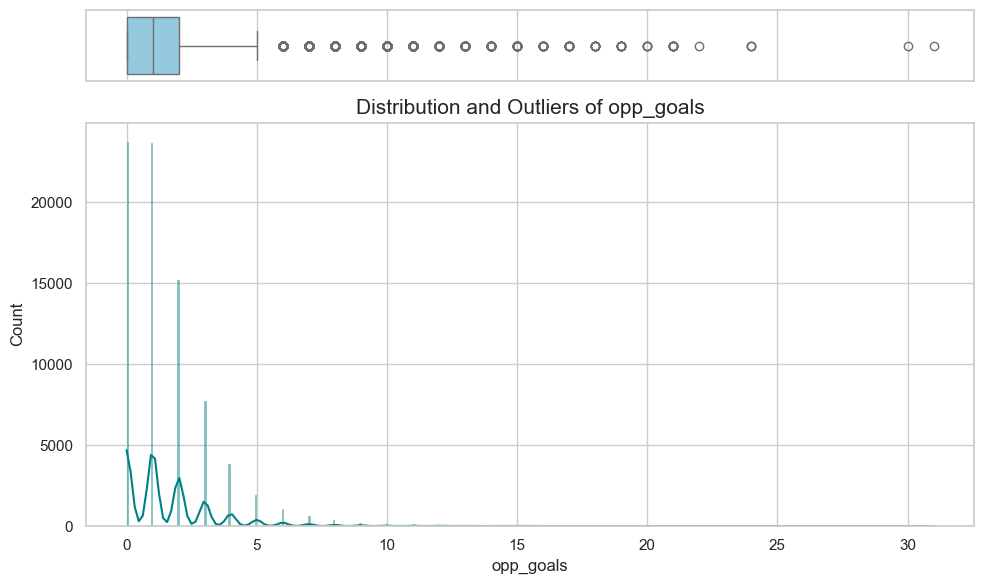

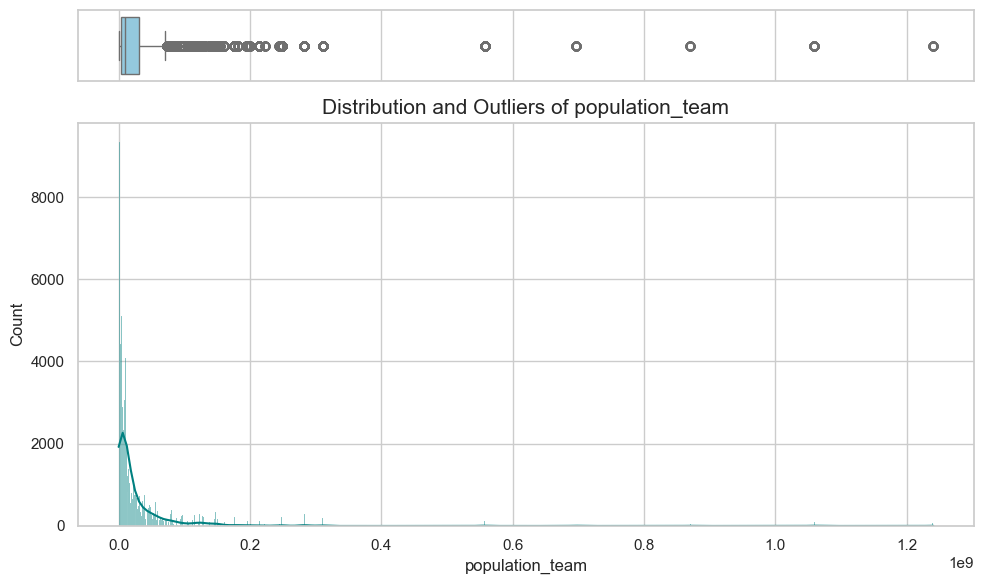

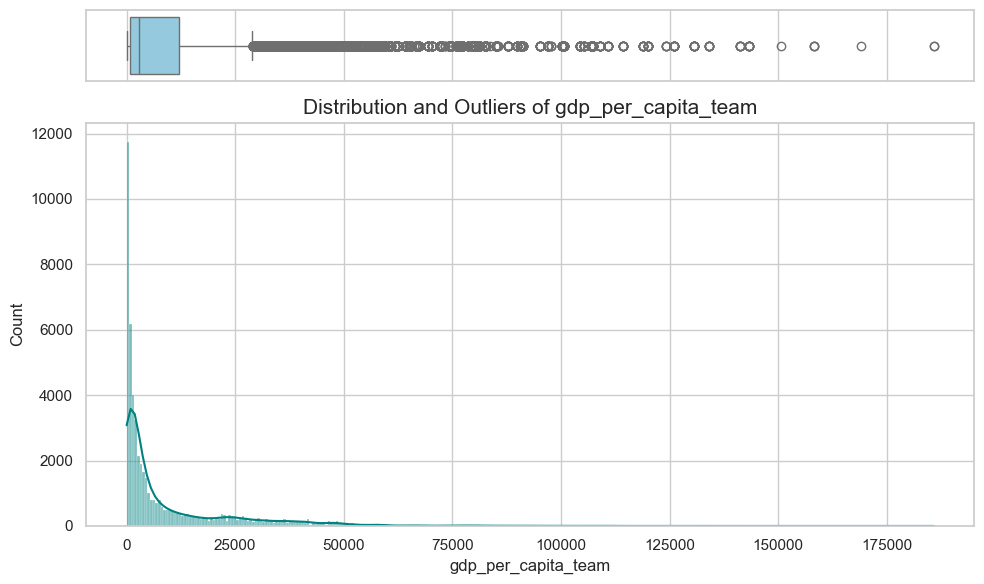

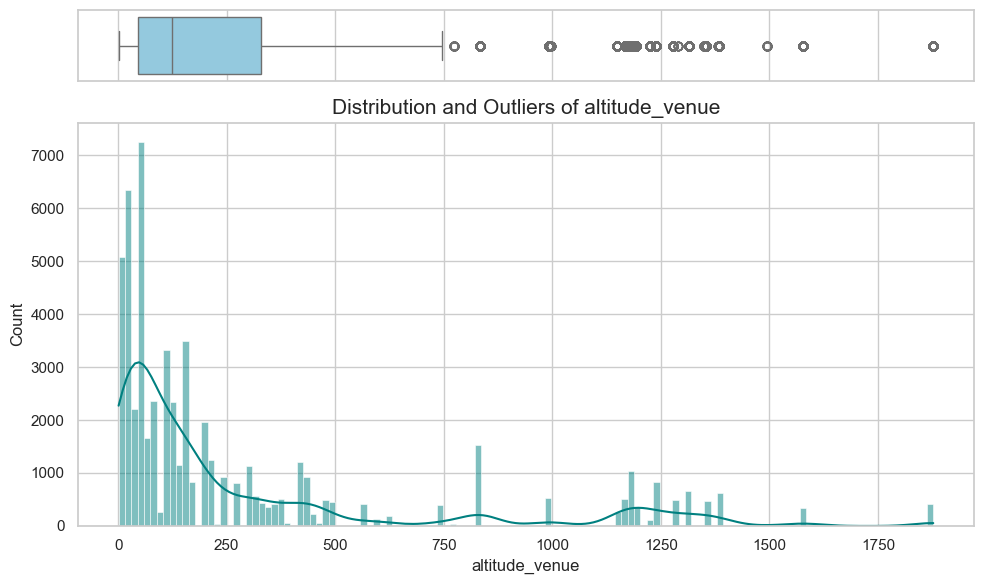

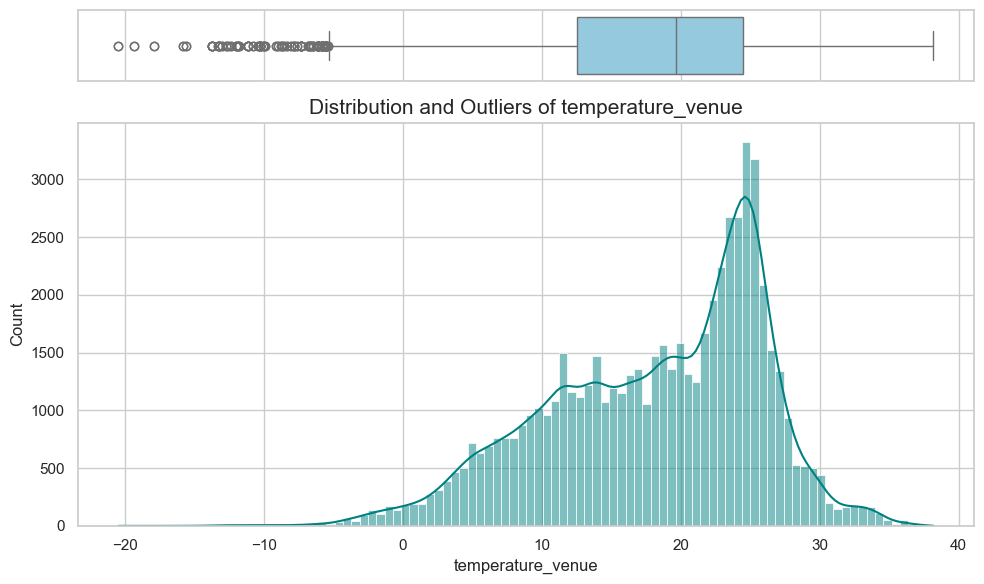

In [10]:
# Visualisasi Distribusi dan Outlier untuk fitur utama
main_num_features = ['team_goals', 'opp_goals', 'population_team', 'gdp_per_capita_team', 'altitude_venue', 'temperature_venue']

for col in main_num_features:
    if col in train.columns:
        fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)}, figsize=(10, 6))
        
        sns.boxplot(data=train, x=col, ax=ax_box, color='skyblue')
        sns.histplot(data=train, x=col, ax=ax_hist, kde=True, color='teal')
        
        ax_box.set(xlabel='')
        ax_hist.set_title(f'Distribution and Outliers of {col}', fontsize=15)
        plt.tight_layout()
        plt.show()

### 1.2 Categorical Variables
Mengecek frekuensi, proporsi, dan kardinalitas.



- Analysis for Id -
Cardinality: 78772 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
Id,,
M000001_England,1,0.0
W001619_Italy,1,0.0
M024640_Spain,1,0.0
M024640_Slovenia,1,0.0
M024639_Sudan,1,0.0
M024639_Liberia,1,0.0
W001620_Czech Republic,1,0.0
W001620_Croatia,1,0.0
W001619_Ukraine,1,0.0


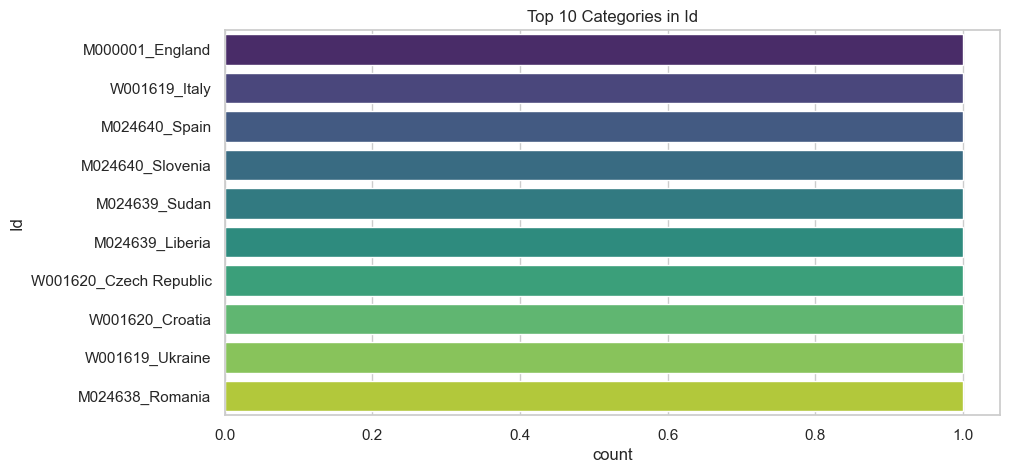


- Analysis for match_id -
Cardinality: 39386 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
match_id,,
M000001,2,0.0
M024641,2,0.0
M024636,2,0.0
M024637,2,0.0
M024638,2,0.0
W001619,2,0.0
W001620,2,0.0
M024639,2,0.0
M024640,2,0.0


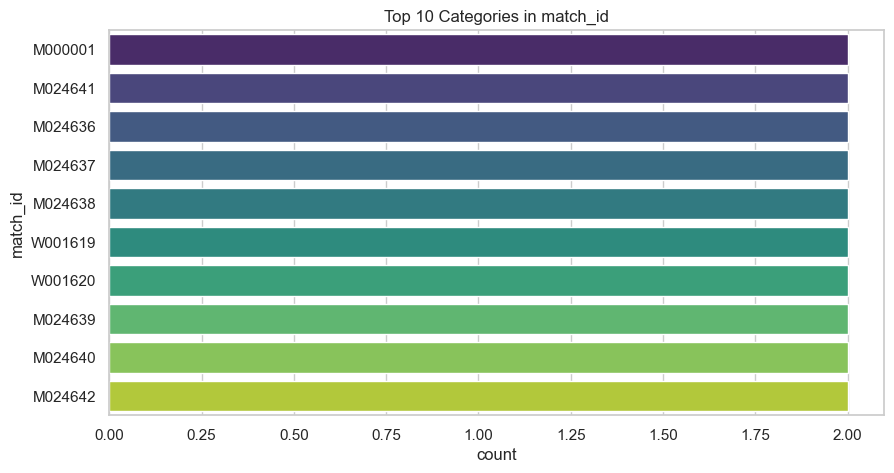


- Analysis for gender -
Cardinality: 2 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
gender,,
M,69966,88.82
W,8806,11.18


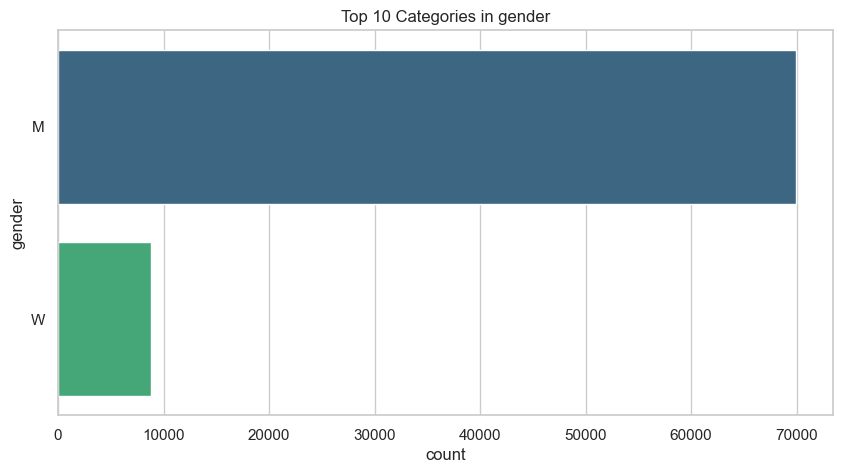


- Analysis for team -
Cardinality: 294 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
team,,
Sweden,1207,1.53
England,1090,1.38
Germany,1068,1.36
Norway,1006,1.28
Brazil,987,1.25
Denmark,975,1.24
Hungary,946,1.20
South Korea,945,1.20
Argentina,933,1.18


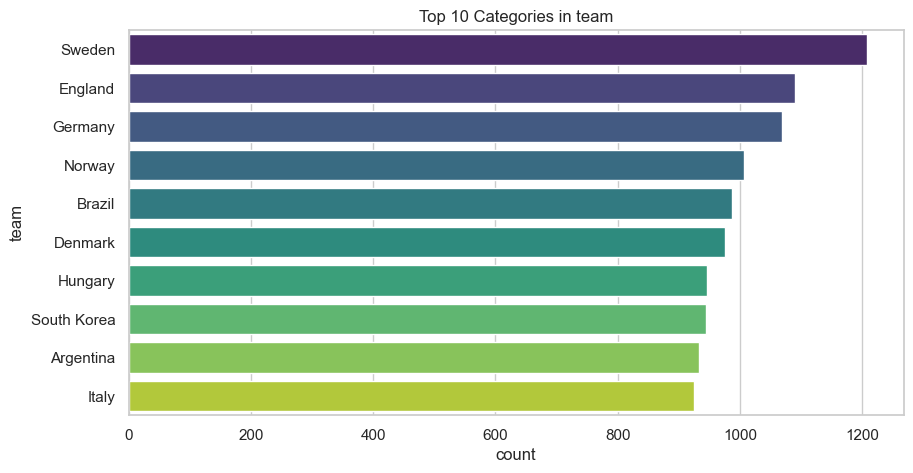


- Analysis for opponent -
Cardinality: 294 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
opponent,,
Sweden,1207,1.53
England,1090,1.38
Germany,1068,1.36
Norway,1006,1.28
Brazil,987,1.25
Denmark,975,1.24
Hungary,946,1.20
South Korea,945,1.20
Argentina,933,1.18


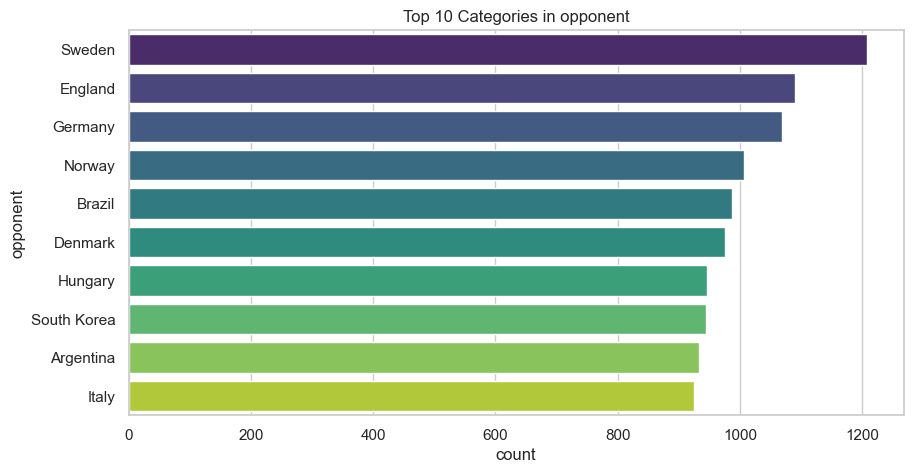


- Analysis for tournament -
Cardinality: 186 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
tournament,,
Friendly,28006,35.55
FIFA World Cup qualification,11934,15.15
UEFA Euro qualification,5698,7.23
African Cup of Nations qualification,2734,3.47
FIFA World Cup,1904,2.42
Copa América,1660,2.11
AFC Asian Cup qualification,1264,1.60
Merdeka Tournament,1190,1.51
British Home Championship,1046,1.33


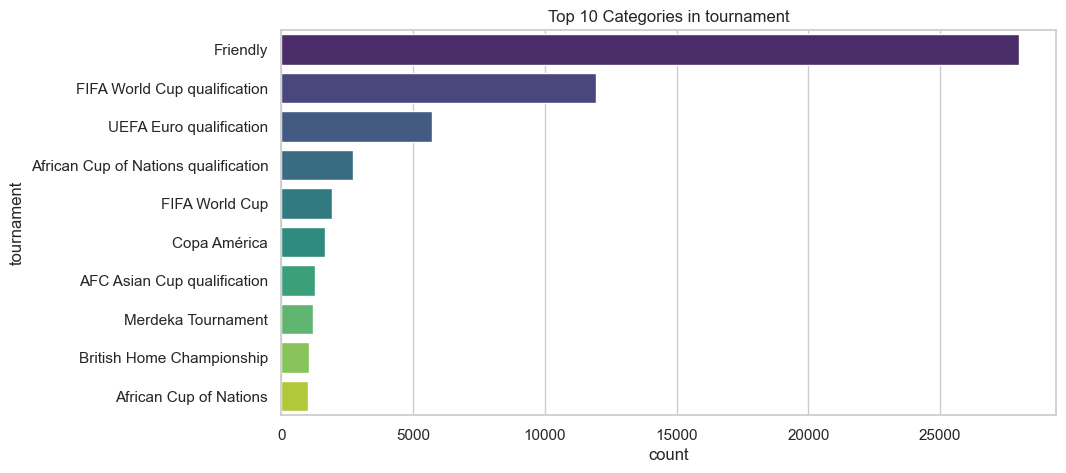


- Analysis for venue_country -
Cardinality: 268 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
venue_country,,
United States,2132,2.71
Malaysia,1526,1.94
France,1472,1.87
Thailand,1404,1.78
Portugal,1358,1.72
Sweden,1284,1.63
England,1272,1.61
Germany,1260,1.60
Italy,1108,1.41


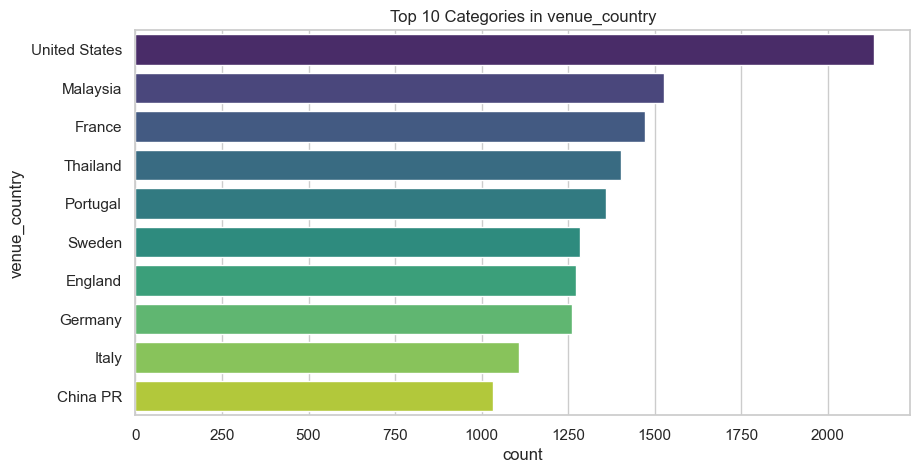


- Analysis for confederation_team -
Cardinality: 7 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
confederation_team,,
UEFA,26916,34.17
AFC,15245,19.35
CAF,14503,18.41
CONCACAF,7716,9.80
Unknown,6403,8.13
CONMEBOL,6327,8.03
OFC,1662,2.11


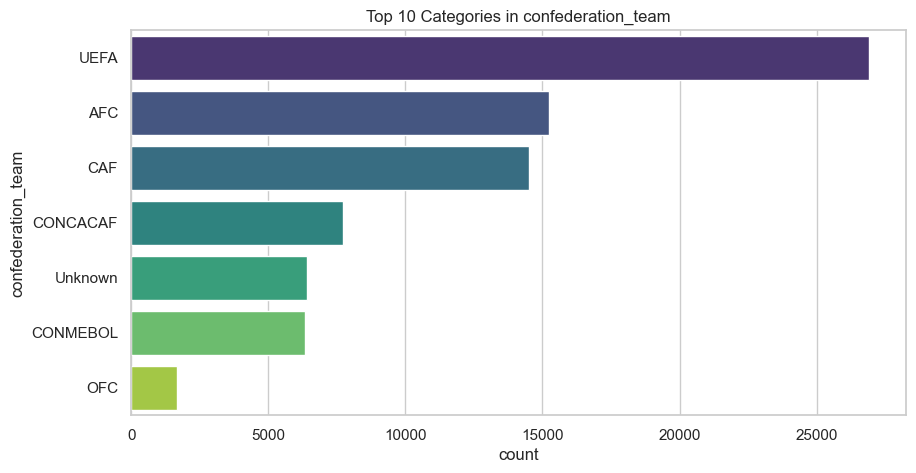


- Analysis for confederation_opp -
Cardinality: 7 unique values
Missing Values: 0 (0.00%)


,Count,Percentage (%)
confederation_opp,,
UEFA,26916,34.17
AFC,15245,19.35
CAF,14503,18.41
CONCACAF,7716,9.80
Unknown,6403,8.13
CONMEBOL,6327,8.03
OFC,1662,2.11


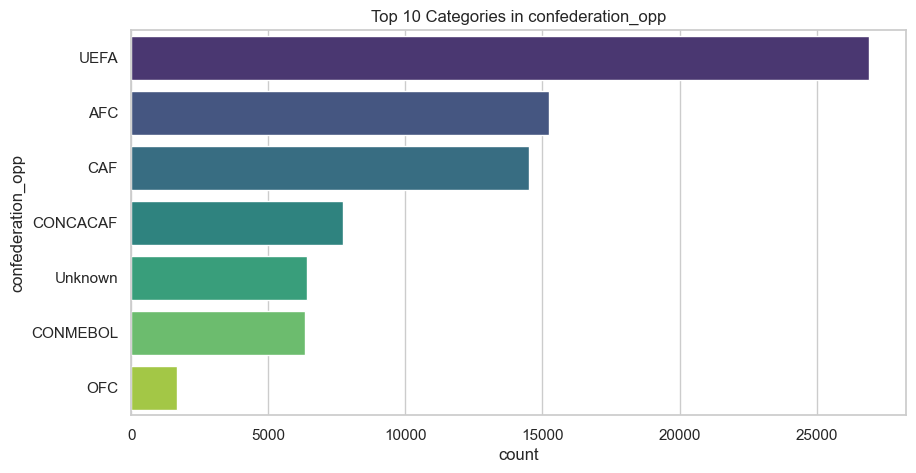

In [11]:
cat_cols = train.select_dtypes(include=['object', 'category']).columns.tolist()
if 'date' in cat_cols: cat_cols.remove('date') 

for col in cat_cols:
    print(f"\n- Analysis for {col} -")
    print(f"Cardinality: {train[col].nunique()} unique values")
    
    # Missing value check
    missing = train[col].isnull().sum()
    print(f"Missing Values: {missing} ({missing/len(train)*100:.2f}%)")
    
    counts = train[col].value_counts().head(10)
    proportions = train[col].value_counts(normalize=True).head(10) * 100
    
    summary_df = pd.DataFrame({'Count': counts, 'Percentage (%)': proportions.round(2)})
    display(summary_df)
    
    # Plot top 10 categories
    plt.figure(figsize=(10, 5))
    sns.countplot(data=train, y=col, order=train[col].value_counts().iloc[:10].index, palette='viridis')
    plt.title(f'Top 10 Categories in {col}')
    plt.show()

## 2. Multivariate Analysis

### 2.1 Numerical vs Numerical
Melihat hubungan antar variabel numerik.


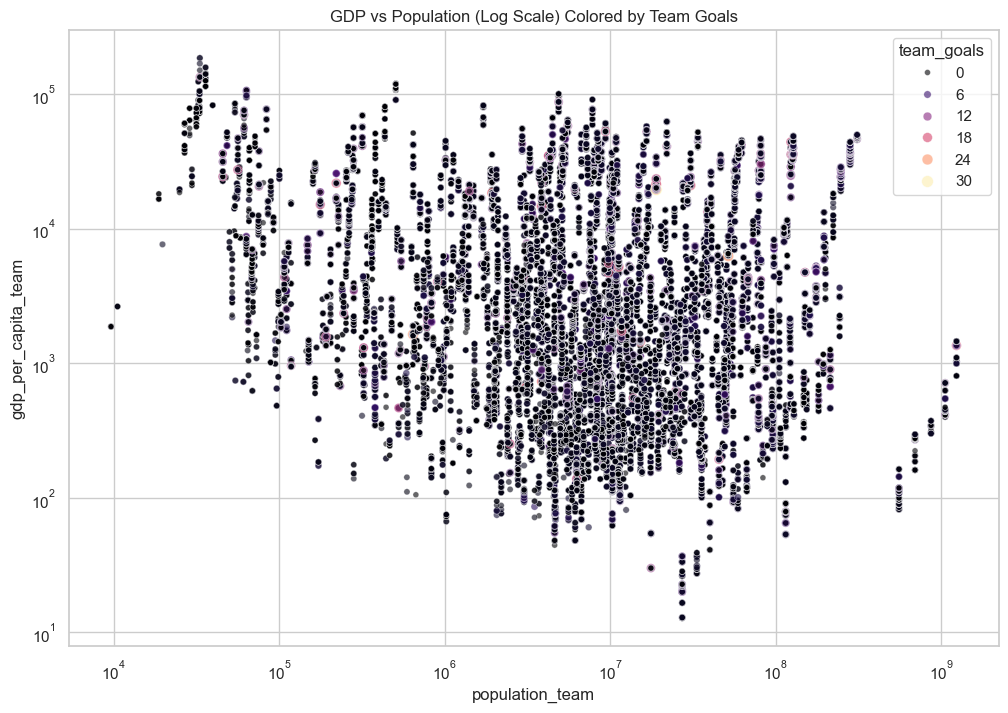

In [12]:
# Scatter plot Population vs GDP with Team Goals color coding
plt.figure(figsize=(12, 8))
sns.scatterplot(data=train, x='population_team', y='gdp_per_capita_team', 
                hue='team_goals', size='team_goals', palette='magma', alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.title('GDP vs Population (Log Scale) Colored by Team Goals')
plt.show()

### 2.3 Categorical vs Categorical
Hubungan antar variabel kategorikal.


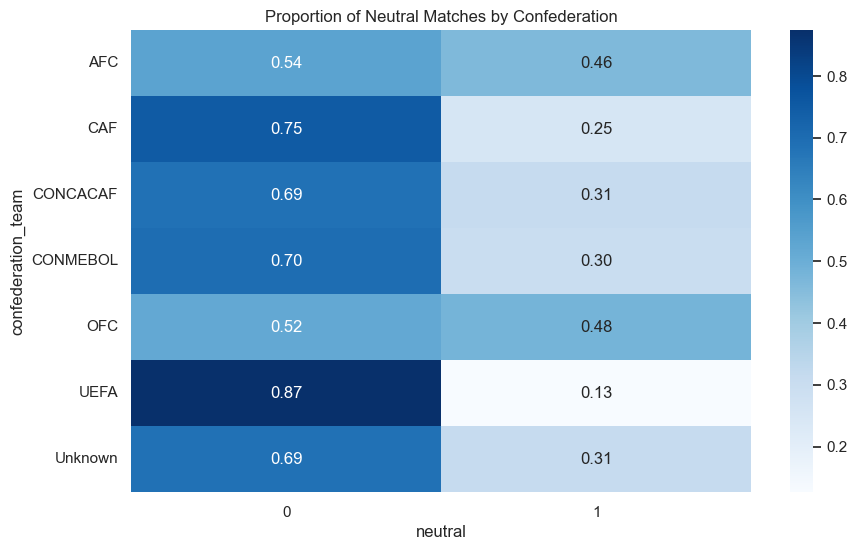

In [13]:
# Heatmap Confederation vs Neutral Match
ct = pd.crosstab(train['confederation_team'], train['neutral'], normalize='index')
plt.figure(figsize=(10, 6))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues')
plt.title('Proportion of Neutral Matches by Confederation')
plt.show()

### 1.3 Visualisasi Missing Values
Melihat persentase data yang hilang pada setiap kolom.


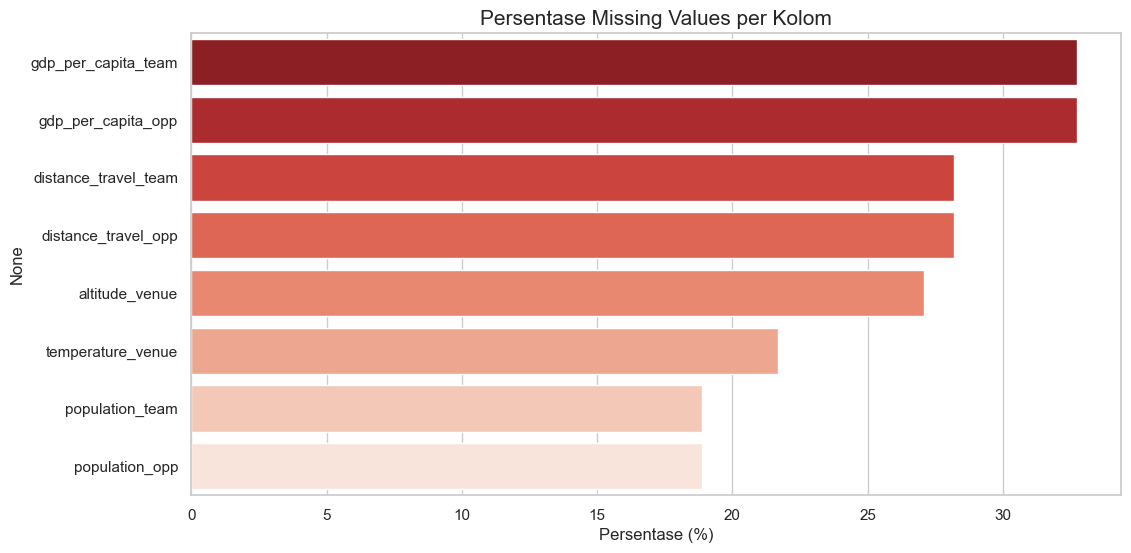

In [14]:
missing_data = train.isnull().sum() / len(train) * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

if not missing_data.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_data.values, y=missing_data.index, palette='Reds_r')
    plt.title('Persentase Missing Values per Kolom', fontsize=15)
    plt.xlabel('Persentase (%)')
    plt.show()
else:
    print('Tidak ada missing values.')

### 1.4 Identifikasi Outlier (IQR Method)
Menghitung jumlah outlier menggunakan rentang interkuartil (IQR).


In [15]:
def count_outliers(df, cols):
    results = []
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        n_outliers = len(df[(df[col] < lower_bound) | (df[col] > upper_bound)])
        results.append({'Column': col, 'Outliers': n_outliers, 'Percentage (%)': round(n_outliers/len(df)*100, 2)})
    return pd.DataFrame(results)

num_cols_for_outliers = ['team_goals', 'opp_goals', 'population_team', 'gdp_per_capita_team', 'altitude_venue', 'temperature_venue']
display(count_outliers(train.dropna(subset=num_cols_for_outliers), num_cols_for_outliers))

,Column,Outliers,Percentage (%)
0,team_goals,1112,2.75
1,opp_goals,1076,2.66
2,population_team,4667,11.53
3,gdp_per_capita_team,4532,11.20
4,altitude_venue,6502,16.07
5,temperature_venue,61,0.15


## 2.4 Analisis Hubungan Tambahan (Multivariate)
Eksplorasi lebih dalam antara fitur kekuatan tim dan hasil pertandingan.


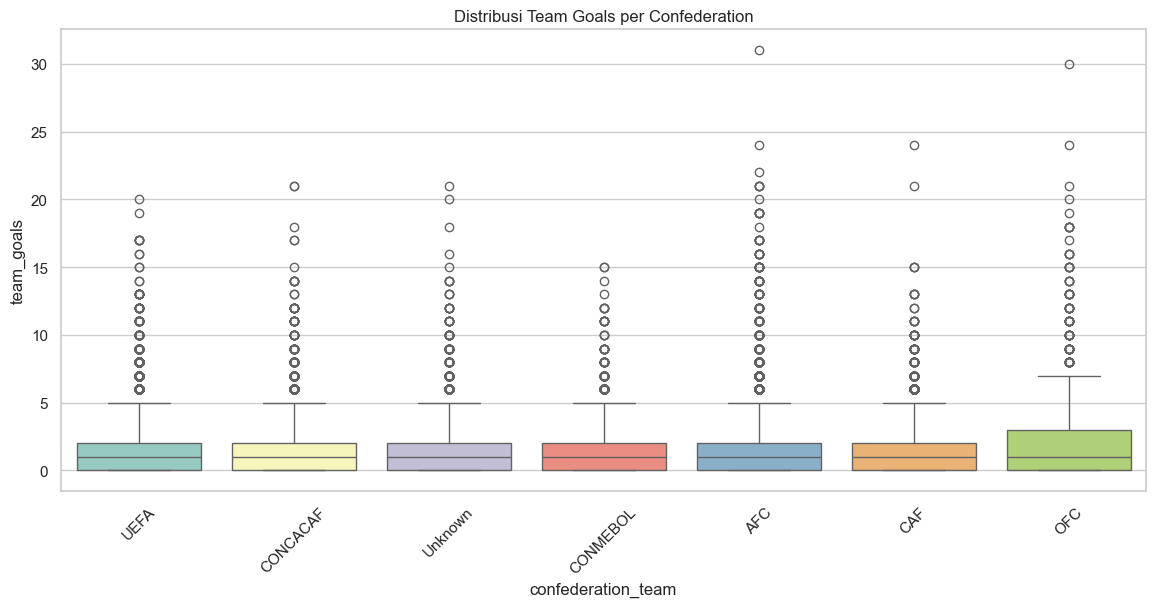

In [16]:
# Hubungan antara Confederation dan Goals
plt.figure(figsize=(14, 6))
sns.boxplot(data=train, x='confederation_team', y='team_goals', palette='Set3')
plt.title('Distribusi Team Goals per Confederation')
plt.xticks(rotation=45)
plt.show()

### 2.5 Analisis Simetri (Team vs Opponent Goals)
Melihat korelasi antara gol tim dan lawan.


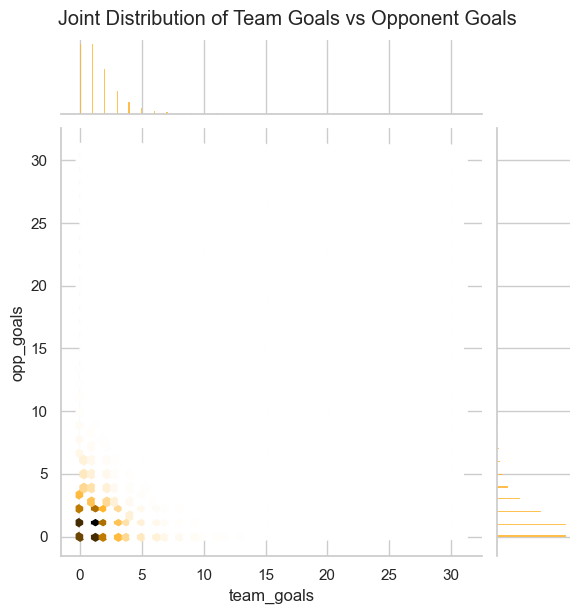

In [17]:
# Joint plot gol tim vs gol lawan
sns.jointplot(data=train, x='team_goals', y='opp_goals', kind='hex', color='orange')
plt.suptitle('Joint Distribution of Team Goals vs Opponent Goals', y=1.02)
plt.show()

## Time-based Analysis


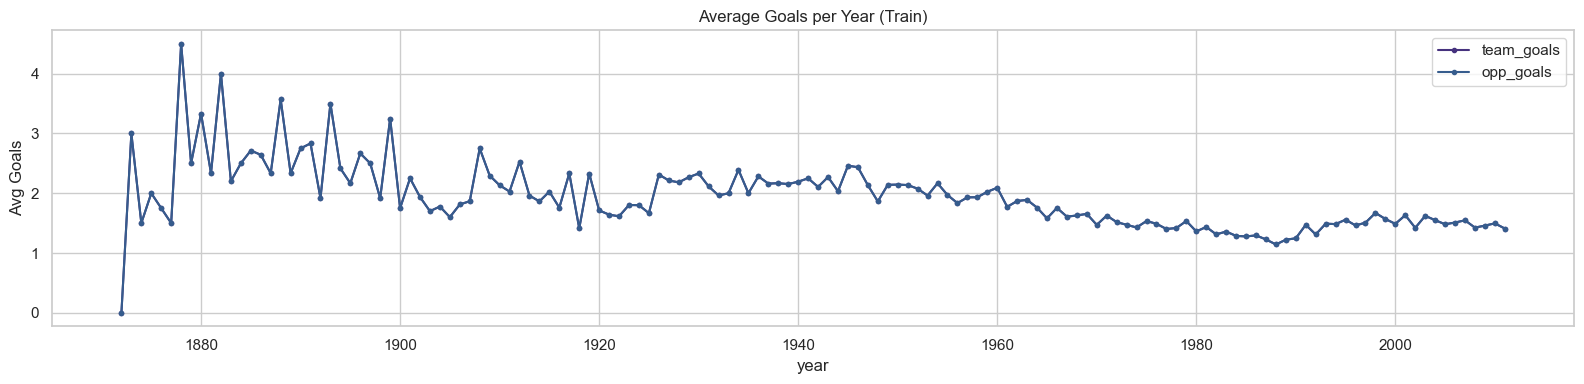

In [18]:
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])

train['year'] = train['date'].dt.year
yearly = train.groupby('year')[['team_goals','opp_goals']].mean()
fig, ax = plt.subplots(figsize=(16, 4))
yearly.plot(ax=ax, marker='o', markersize=3)
ax.set_title('Average Goals per Year (Train)'); ax.set_ylabel('Avg Goals')
plt.tight_layout(); plt.show()


## Outlier & Special Value Check


In [19]:
# altitude_venue has -9999 sentinel values
print("altitude_venue == -9999 in train:", (train['altitude_venue']==-9999).sum())
print("altitude_venue == -9999 in test :", (test['altitude_venue']==-9999).sum())
print()
# Check extreme goals
print("team_goals > 10:", (train['team_goals']>10).sum())
print("Max team_goals:", train['team_goals'].max(), "| Max opp_goals:", train['opp_goals'].max())


altitude_venue == -9999 in train: 0
altitude_venue == -9999 in test : 296

team_goals > 10: 323
Max team_goals: 31 | Max opp_goals: 31


## SECTION 1: IMPORTS AND CONFIGURATION


In [20]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import optuna
from scipy.stats import poisson
from collections import defaultdict
import os
import warnings
warnings.filterwarnings('ignore')

# Global Constants
INITIAL_ELO = 1500.0
HOME_ADV = 50
ELO_HOME_BONUS = 100.0

NON_FIFA_KEYWORDS = [
    'viva', 'conifa', 'wild cup', 'elf cup', 'island games', 
    'dragon cup', 'unaf', 'abcs', 'nile basin'
]

## SECTION 2: UTILITY FUNCTIONS


In [21]:
def calc_awmae(yt, yo, pt, po, w):
    # Augmented Weighted Mean Absolute Error calculation
    mae = (np.abs(yt - pt) + np.abs(yo - po)) / 2
    ex = (yt == pt) & (yo == po)
    ou = np.sign(yt - yo) == np.sign(pt - po)
    gd = (yt - yo) == (pt - po)
    pen = 0.3 * (1 - ex) + 0.25 * (1 - ou) + 0.15 * (1 - gd)
    loss = ((mae + pen) * np.where(ou, 1.0, 1.5)) ** 1.5
    return (w * loss).sum() / w.sum()

def get_tournament_weight(tournament):
    # Official competition weights for the metric
    t = str(tournament).lower()
    if 'world cup' in t and 'qual' not in t:
        return 2.00
    if ('afc' in t or 'asian cup' in t) and 'qual' not in t:
        return 1.80
    if 'friendly' in t:
        return 0.96
    return 1.20

def get_elo_k_factor(tournament):
    # K factor determined by tournament importance
    t = str(tournament).lower()
    if 'world cup' in t and 'qual' not in t:
        return 60
    if any(x in t for x in ['euro', 'copa america', 'asian cup', 'africa cup',
                            'nations league', 'gold cup', 'olympic']):
        if 'qual' not in t:
            return 50
    if 'qual' in t:
        return 40
    if 'friendly' in t:
        return 20
    return 30

def elo_update(elo_a, elo_b, goals_a, goals_b, k, is_home_a, neutral):
    # Standard ELO update logic with home advantage
    hb = ELO_HOME_BONUS if is_home_a and not neutral else 0.0
    dr = elo_a + hb - elo_b
    we = 1 / (1 + 10 ** (-dr / 400))
    w = 1.0 if goals_a > goals_b else 0.5 if goals_a == goals_b else 0.0
    gd = abs(goals_a - goals_b)
    g = 1.0 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
    delta = k * g * (w - we)
    return elo_a + delta, elo_b - delta

def find_optimal_scores_vectorized(lt, lo, pc, is_male, bt, bo, dmm, dmw, cw, max_goals=12):
    # Vectorized search for scores that minimize expected AWMAE loss
    n = len(lt)
    G = max_goals + 1
    goals = np.arange(G)
    lt_mod = lt.reshape(-1, 1) * bt
    lo_mod = lo.reshape(-1, 1) * bo
    
    prob_t = poisson.pmf(goals, lt_mod)
    prob_o = poisson.pmf(goals, lo_mod)
    joint_p = prob_t[:, :, np.newaxis] * prob_o[:, np.newaxis, :]
    
    tg_g, og_g = np.meshgrid(goals, goals, indexing='ij')
    mask_win, mask_draw, mask_loss = (tg_g > og_g), (tg_g == og_g), (tg_g < og_g)
    
    swp = np.sum(joint_p[:, mask_win], axis=1, keepdims=True)
    sdp = np.sum(joint_p[:, mask_draw], axis=1, keepdims=True)
    slp = np.sum(joint_p[:, mask_loss], axis=1, keepdims=True)
    
    p0 = (1 - cw) * sdp.squeeze() + cw * pc[:, 0]
    p1 = (1 - cw) * swp.squeeze() + cw * pc[:, 1]
    p2 = (1 - cw) * slp.squeeze() + cw * pc[:, 2]
    
    jw = joint_p * mask_win[np.newaxis, :, :]
    jd = joint_p * mask_draw[np.newaxis, :, :]
    jl = joint_p * mask_loss[np.newaxis, :, :]
    
    jw *= (p1[:, np.newaxis, np.newaxis] / np.where(swp == 0, 1e-9, swp)[:, :, np.newaxis])
    jd *= (p0[:, np.newaxis, np.newaxis] / np.where(sdp == 0, 1e-9, sdp)[:, :, np.newaxis])
    jl *= (p2[:, np.newaxis, np.newaxis] / np.where(slp == 0, 1e-9, slp)[:, :, np.newaxis])
    
    jd *= np.where(is_male, dmm, dmw)[:, np.newaxis, np.newaxis]
    
    joint = jw + jd + jl
    s = np.sum(joint, axis=(1, 2), keepdims=True)
    joint = np.where(s == 0, 0, joint / s)
    
    candidates = [(p_t, p_o) for p_t in range(7) for p_o in range(7)]
    candidates += [(8, 0), (10, 0), (0, 8), (0, 10)]
    
    losses = []
    for pt, po in candidates:
        mae = (np.abs(tg_g - pt) + np.abs(og_g - po)) / 2.0
        ex = (tg_g == pt) & (og_g == po)
        ou = np.sign(tg_g - og_g) == np.sign(pt - po)
        gd_m = (tg_g - og_g) == (pt - po)
        pen = 0.3 * (1 - ex) + 0.25 * (1 - ou) + 0.15 * (1 - gd_m)
        losses.append(((mae + pen) * np.where(ou, 1.0, 1.5)) ** 1.5)
        
    losses = np.array(losses)
    expected_loss = np.tensordot(joint, losses, axes=([1, 2], [1, 2]))
    idx = np.argmin(expected_loss, axis=1)
    return np.array([candidates[i][0] for i in idx]), np.array([candidates[i][1] for i in idx])

## SECTION 3: FEATURE ENGINEERING


In [22]:
def build_diff_features(df):
    df = df.copy()
    pairs = [
        ('points_last5_diff', 'team_points_last5', 'opp_points_last5'),
        ('gd_last5_diff', 'team_gd_last5', 'opp_gd_last5'),
        ('points_last10_diff', 'team_points_last10', 'opp_points_last10'),
        ('win_rate_last10_diff', 'team_win_rate_last10', 'opp_win_rate_last10'),
        ('avg_goals_last5_diff', 'team_avg_goals_last5', 'opp_avg_goals_last5'),
        ('avg_conceded_last5_diff', 'team_avg_conceded_last5', 'opp_avg_conceded_last5'),
        ('gdp_diff', 'gdp_per_capita_team', 'gdp_per_capita_opp'),
        ('population_diff', 'population_team', 'population_opp'),
    ]
    for col, a, b in pairs:
        if a in df.columns and b in df.columns:
            df[col] = df[a] - df[b]
    return df

def add_time_features(df):
    df = df.copy()
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek
    return df

def get_state_features(history, h2h, elo, g, t1, t2):
    h1, h2 = history[(g, t1)], history[(g, t2)]
    gf1 = np.mean([x[0] for x in h1[-5:]]) if h1 else 1.3
    ga1 = np.mean([x[1] for x in h1[-5:]]) if h1 else 1.3
    gf2 = np.mean([x[0] for x in h2[-5:]]) if h2 else 1.3
    ga2 = np.mean([x[1] for x in h2[-5:]]) if h2 else 1.3
    
    win_rate1 = sum(1 for x in h1[-10:] if x[0] > x[1]) / len(h1[-10:]) if h1 else 0.33
    win_rate2 = sum(1 for x in h2[-10:] if x[0] > x[1]) / len(h2[-10:]) if h2 else 0.33
    
    e1, e2 = elo[(g, t1)], elo[(g, t2)]
    h_gd = np.mean(h2h[(g, t1, t2)][-5:]) if h2h[(g, t1, t2)] else 0.0
    
    return [
        e1, e2, e1 - e2, 
        gf1, ga1, gf1 - ga1,
        gf2, ga2, gf2 - ga2,
        win_rate1, win_rate2, win_rate1 - win_rate2,
        h_gd
    ]

In [23]:
HOME_ADV = 50

NON_FIFA_KEYWORDS = [
    'viva', 'conifa', 'wild cup', 'elf cup', 'island games',
    'dragon cup', 'unaf', 'abcs', 'nile basin'
]

SOCIOECONOMIC_FEATURES = [
    'population_team', 'population_opp',
    'gdp_per_capita_team', 'gdp_per_capita_opp'
]

TEAM_STATE_COLS = [
    'elo_team', 'team_points_last5', 'team_gd_last5',
    'team_points_last10', 'team_avg_goals_last5',
    'team_avg_conceded_last5', 'team_win_rate_last10'
]

def repair_elo_misalignment(df):
    df = df.copy()
    if 'match_id' not in df.columns:
        return df
    match_id = df['match_id'].copy()
    req = {'match_id', 'team', 'opponent', 'elo_team', 'elo_opponent'}
    if not req.issubset(df.columns):
        return df

    def align_match(g):
        if len(g) > 1:
            e_team = g.iloc[0]['elo_team']
            e_opp  = g.iloc[0]['elo_opponent']
            g.loc[g.index[0], 'elo_team'] = e_team
            g.loc[g.index[0], 'elo_opponent'] = e_opp
            g.loc[g.index[1], 'elo_team'] = e_opp
            g.loc[g.index[1], 'elo_opponent'] = e_team
        return g

    df = df.groupby('match_id', group_keys=False).apply(align_match)
    df['elo_diff'] = df['elo_team'] - df['elo_opponent']
    df.drop(columns=['match_id'], inplace=True)
    df.insert(0, 'match_id', match_id)
    return df

def add_tournament_weight(df, freq_map=None):
    if 'tournament' not in df.columns:
        return df
    df = df.copy()
    def base_weight(x):
        x = str(x)
        if "Friendly" in x: return 0.8
        elif "World Cup" in x: return 2.0
        elif "Euro" in x or "AFC" in x or "Cup of Nations" in x: return 1.6
        elif "qualification" in x.lower(): return 1.3
        else: return 1.2
    df['tournament_weight'] = df['tournament'].apply(base_weight)
    if freq_map is not None:
        import numpy as np
        df['tournament_weight'] *= df['tournament'].map(
            lambda x: -np.log(freq_map.get(x, 1e-6) + 1e-6)
        )
    return df

def adding_features(df):
    df = df.copy()
    if 'elo_diff' in df.columns and 'is_home' in df.columns:
        df['elo_home_adv'] = df['elo_diff'] + df['is_home'] * HOME_ADV
    if 'gender' in df.columns:
        df['is_male'] = df['gender'].map({'M': 1, 'W':0})
    if 'elo_team' in df.columns:
        df['elo_team_missing'] = df['elo_team'].isna().astype(int)
    if 'elo_opponent' in df.columns:
        df['elo_opp_missing']  = df['elo_opponent'].isna().astype(int)
    return df

def removing_features(df):
    df = df.copy()
    cols_to_drop = [c for c in ['gender', 'confederation_team', 'confederation_opp', 'venue_country'] if c in df.columns]
    df = df.drop(columns=cols_to_drop)
    return df

def add_venue_features(df):
    df = df.copy()
    if 'venue_country' in df.columns and 'team' in df.columns:
        df['is_home_country'] = (df['venue_country'] == df['team']).astype(int)
        df['is_opponent_home_country'] = (df['venue_country'] == df['opponent']).astype(int)
    if 'confederation_team' in df.columns and 'confederation_opp' in df.columns:
        df['same_confederation'] = (df['confederation_team'] == df['confederation_opp']).astype(int)
        df['is_intercontinental'] = (df['confederation_team'] != df['confederation_opp']).astype(int)
    if 'altitude_venue' in df.columns:
        import numpy as np
        df['altitude_venue'] = df['altitude_venue'].replace(-9999, np.nan)
    return df

def add_non_fifa_flag(df):
    if 'tournament' not in df.columns:
        return df
    df = df.copy()
    pattern = '|'.join(NON_FIFA_KEYWORDS)
    df['is_non_fifa'] = df['tournament'].fillna('').str.lower().str.contains(pattern, regex=True).astype('int8')
    return df

def add_era(df):
    if 'year' not in df.columns:
        return df
    df = df.copy()
    import numpy as np
    conditions = [df['year'].isna(), df['year'] < 1950, df['year'] < 1980, df['year'] < 2000]
    choices = ['Unknown', 'Pre-1950', '1950-1979', '1980-1999']
    df['era'] = np.select(conditions, choices, default='2000+')
    return df

def special_flags(df):
    df = df.copy()
    if 'population_team' in df.columns:
        df['is_microstate_team'] = (df['population_team'] < 1000000).astype(int)
    if 'population_opp' in df.columns:
        df['is_microstate_opp'] = (df['population_opp'] < 1000000).astype(int)
    return df

def log_transform_socioeconomic(df):
    df = df.copy()
    import numpy as np
    for col in SOCIOECONOMIC_FEATURES:
        if col in df.columns:
            df[col + '_log'] = np.log1p(df[col].clip(lower=0))
    return df

def build_team_latest_state(df_train):
    df = df_train.sort_values('date')
    cols = ['team', 'date'] + [c for c in TEAM_STATE_COLS if c in df.columns]
    latest = df[cols].dropna(subset=['team']).groupby('team', as_index=False).tail(1).set_index('team')
    return latest[[c for c in TEAM_STATE_COLS if c in latest.columns]]

def apply_team_and_opp_state(df_test, team_state):
    df = df_test.copy()
    for col in [c for c in TEAM_STATE_COLS if c in team_state.columns]:
        df[col] = df['team'].map(team_state[col])
    rename_map = {
        'elo_team': 'elo_opponent',
        'team_points_last5': 'opp_points_last5',
        'team_gd_last5': 'opp_gd_last5',
        'team_points_last10': 'opp_points_last10',
        'team_avg_goals_last5': 'opp_avg_goals_last5',
        'team_avg_conceded_last5': 'opp_avg_conceded_last5',
        'team_win_rate_last10': 'opp_win_rate_last10'
    }
    for src, dst in rename_map.items():
        if src in team_state.columns:
            df[dst] = df['opponent'].map(team_state[src])
    return df

def add_days_since_last_match(df_test):
    if 'date' not in df_test.columns:
        return df_test
    df = df_test.copy()
    df['_original_order'] = range(len(df))
    df = df.sort_values('date')
    if 'team' in df.columns:
        df['days_since_last_match_team'] = df.groupby('team')['date'].diff().dt.days
    if 'opponent' in df.columns:
        df['days_since_last_match_opp'] = df.groupby('opponent')['date'].diff().dt.days
    df = df.sort_values('_original_order').drop(columns=['_original_order'])
    return df

def fill_defaults(df):
    df = df.copy()
    if 'elo_team' in df.columns:
        df['elo_team_missing'] = df['elo_team'].isna().astype(int)
        df['elo_team'] = df['elo_team'].fillna(1500)
    if 'elo_opponent' in df.columns:
        df['elo_opp_missing']  = df['elo_opponent'].isna().astype(int)
        df['elo_opponent'] = df['elo_opponent'].fillna(1500)
    return df

def enrich_test_from_train(df_test, df_train):
    team_state = build_team_latest_state(df_train)
    df_test = apply_team_and_opp_state(df_test, team_state)
    df_test = add_days_since_last_match(df_test)
    df_test = fill_defaults(df_test)
    return df_test

def engineer_features(df):
    df = repair_elo_misalignment(df)
    df = build_diff_features(df)
    df = add_tournament_weight(df)
    df = add_venue_features(df)
    df = add_time_features(df)
    df = add_non_fifa_flag(df)
    df = add_era(df)
    df = special_flags(df)
    df = log_transform_socioeconomic(df)
    df = adding_features(df)
    df = removing_features(df)
    return df


## SECTION 4: MAIN PIPELINE


In [24]:
print("Loading data")
train['date'] = pd.to_datetime(train['date'])
test['date'] = pd.to_datetime(test['date'])
train = train.sort_values(['date', 'match_id']).reset_index(drop=True)
test = test.sort_values(['date', 'match_id']).reset_index(drop=True)

print("Reconstructing historical Elo states")
elo = defaultdict(lambda: INITIAL_ELO)
train_elo_storage = []

# We ONLY need to calculate Elo dynamically in chronological order
for i, row in train.iterrows():
    g, t1, t2 = row['gender'], row['team'], row['opponent']
    e1, e2 = elo[(g, t1)], elo[(g, t2)]
    
    train_elo_storage.append([e1, e2])
    
    # Update states with actual outcomes
    tg, og = row['team_goals'], row['opp_goals']
    kf = get_elo_k_factor(row['tournament'])
    ne1, ne2 = elo_update(e1, e2, tg, og, kf, row['is_home']==1, row['neutral']==1)
    elo[(g, t1)], elo[(g, t2)] = ne1, ne2

elo_df = pd.DataFrame(train_elo_storage, columns=['elo_team', 'elo_opponent'])
train['elo_team'] = elo_df['elo_team']
train['elo_opponent'] = elo_df['elo_opponent']

print("Applying Feature Engineering to Train")
train = engineer_features(train)

print("Applying Feature Engineering to Test")
test = enrich_test_from_train(test, train)
test = engineer_features(test)

print("Preparing features for modeling")
# Make sure w is set from tournament_weight
if 'tournament_weight' in train.columns:
    train['w'] = train['tournament_weight']
else:
    train['w'] = train['tournament'].apply(get_tournament_weight)

y_c = np.where(train['team_goals'] > train['opp_goals'], 1, 
              np.where(train['team_goals'] < train['opp_goals'], 2, 0))

import numpy as np
# All features are numeric columns minus targets and weights
all_features = [c for c in train.select_dtypes(include=[np.number]).columns if c not in ['team_goals', 'opp_goals', 'w', 'outcome_points', 'outcome_gd', 'match_id']]
# Note: we need to ensure test has the exact same features.
missing_cols = set(all_features) - set(test.columns)
for c in missing_cols:
    test[c] = 0
all_features = [c for c in all_features if c in test.columns]

print(f"Total Features used: {len(all_features)}")

print("Training models")
split_idx = int(len(train) * 0.9)
tr_df, val_df = train.iloc[:split_idx], train.iloc[split_idx:]
tr_y_c, val_y_c = y_c[:split_idx], y_c[split_idx:]
    
lgb_params = {'learning_rate': 0.03, 'num_leaves': 63, 'verbose': -1, 'feature_fraction': 0.8}
    
m_t = lgb.train({**lgb_params, 'objective': 'poisson'}, 
                    lgb.Dataset(tr_df[all_features], label=tr_df['team_goals'], weight=tr_df['w']), 1000)
m_o = lgb.train({**lgb_params, 'objective': 'poisson'}, 
                    lgb.Dataset(tr_df[all_features], label=tr_df['opp_goals'], weight=tr_df['w']), 1000)
m_c = lgb.train({**lgb_params, 'objective': 'multiclass', 'num_class': 3}, 
                    lgb.Dataset(tr_df[all_features], label=tr_y_c, weight=tr_df['w']), 1000)

print("Optimizing probability multipliers")
v_lt = m_t.predict(val_df[all_features])
v_lo = m_o.predict(val_df[all_features])
v_pc = m_c.predict(val_df[all_features])

# Is_m mapping
if 'is_male' in val_df.columns:
    v_isms = val_df['is_male'].values
elif 'is_m' in val_df.columns:
    v_isms = val_df['is_m'].values
else:
    v_isms = (val_df['gender'] == 'M').astype(int).values

v_w = val_df['w'].values
v_y_t, v_y_o = val_df['team_goals'].values, val_df['opp_goals'].values

def objective(trial):
    bt = trial.suggest_float('bt', 0.9, 1.2)
    bo = trial.suggest_float('bo', 0.9, 1.2)
    dm = trial.suggest_float('dm', 0.7, 1.3)
    cw = trial.suggest_float('cw', 0.2, 0.8)
    pt, po = find_optimal_scores_vectorized(v_lt, v_lo, v_pc, v_isms, bt, bo, dm, dm, cw)
    return calc_awmae(v_y_t, v_y_o, pt, po, v_w)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)
bp = study.best_params

print("Predicting test set")
t_lt = m_t.predict(test[all_features])
t_lo = m_o.predict(test[all_features])
t_pc = m_c.predict(test[all_features])

if 'is_male' in test.columns:
    t_isms = test['is_male'].values
elif 'is_m' in test.columns:
    t_isms = test['is_m'].values
else:
    t_isms = (test['gender'] == 'M').astype(int).values
    
pt, po = find_optimal_scores_vectorized(t_lt, t_lo, t_pc, t_isms, 
                                        bp['bt'], bp['bo'], bp['dm'], bp['dm'], bp['cw'])
    
final_res = pd.DataFrame({'Id': test['Id'], 'team_goals': pt, 'opp_goals': po})
sample_sub = pd.read_csv('data/sample submission.csv')
submission = sample_sub[['Id']].merge(final_res, on='Id', how='left')
submission.to_csv('submission.csv', index=False)
print("Process complete. Submission saved to submission.csv")


Loading data
Reconstructing historical Elo states
Applying Feature Engineering to Train
Applying Feature Engineering to Test
Preparing features for modeling
Total Features used: 56
Training models
Optimizing probability multipliers


[I 2026-06-06 11:19:48,944] A new study created in memory with name: no-name-4c8d4467-6490-4704-9101-e42434d48cef
[I 2026-06-06 11:19:49,162] Trial 0 finished with value: 2.73266429043218 and parameters: {'bt': 0.966894989271418, 'bo': 0.9870834462346757, 'dm': 0.704714652085522, 'cw': 0.7769187873371222}. Best is trial 0 with value: 2.73266429043218.
[I 2026-06-06 11:19:49,292] Trial 1 finished with value: 2.7854990821620214 and parameters: {'bt': 1.149215895469565, 'bo': 1.1081308268801195, 'dm': 0.904467120799866, 'cw': 0.7692585146813087}. Best is trial 0 with value: 2.73266429043218.
[I 2026-06-06 11:19:49,418] Trial 2 finished with value: 2.723534598063358 and parameters: {'bt': 0.9410892828222606, 'bo': 1.1165428472722194, 'dm': 1.0418087616357548, 'cw': 0.48957759924752126}. Best is trial 2 with value: 2.723534598063358.
[I 2026-06-06 11:19:49,547] Trial 3 finished with value: 2.696905979885437 and parameters: {'bt': 1.00775423763717, 'bo': 0.9461522432525854, 'dm': 0.943751801

Predicting test set
Process complete. Submission saved to submission.csv


In [25]:
# All features including those from build_diff and add_time

all_features = [c for c in train_df.columns if c not in ['date', 'team_goals', 'opp_goals', 'w']]

NameError: name 'train_df' is not defined

## SECTION 5: TRAINING


In [ ]:
print("Training models")
split_idx = int(len(train_df) * 0.9)
tr_df, val_df = train_df.iloc[:split_idx], train_df.iloc[split_idx:]
tr_y_c, val_y_c = y_c[:split_idx], y_c[split_idx:]
    
lgb_params = {'learning_rate': 0.03, 'num_leaves': 63, 'verbose': -1, 'feature_fraction': 0.8}
    
m_t = lgb.train({**lgb_params, 'objective': 'poisson'}, 
                    lgb.Dataset(tr_df[all_features], label=tr_df['team_goals'], weight=tr_df['w']), 1000)
m_o = lgb.train({**lgb_params, 'objective': 'poisson'}, 
                    lgb.Dataset(tr_df[all_features], label=tr_df['opp_goals'], weight=tr_df['w']), 1000)
m_c = lgb.train({**lgb_params, 'objective': 'multiclass', 'num_class': 3}, 
                    lgb.Dataset(tr_df[all_features], label=tr_y_c, weight=tr_df['w']), 1000)

## SECTION 6: OPTIMIZATION


In [ ]:
print("Optimizing probability multipliers")
v_lt = m_t.predict(val_df[all_features])
v_lo = m_o.predict(val_df[all_features])
v_pc = m_c.predict(val_df[all_features])
v_isms = val_df['is_m'].values
v_w = val_df['w'].values
v_y_t, v_y_o = val_df['team_goals'].values, val_df['opp_goals'].values

def objective(trial):
    bt = trial.suggest_float('bt', 0.9, 1.2)
    bo = trial.suggest_float('bo', 0.9, 1.2)
    dm = trial.suggest_float('dm', 0.7, 1.3)
    cw = trial.suggest_float('cw', 0.2, 0.8)
    pt, po = find_optimal_scores_vectorized(v_lt, v_lo, v_pc, v_isms, bt, bo, dm, dm, cw)
    return calc_awmae(v_y_t, v_y_o, pt, po, v_w)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)
bp = study.best_params

## SECTION 7: PREDICTION


In [ ]:
print("Predicting test set")
test_storage = []
for i, row in test.iterrows():
    g, t1, t2 = row['is_male'], row['team'], row['opponent']
    is_m = 1 if g == 'M' else 0
    st = get_state_features(history, h2h, elo, g, t1, t2)
    test_storage.append(st + [
        row['is_home'], row['neutral'], is_m,
        row['population_team'], row['population_opp'],
        row['gdp_per_capita_team'], row['gdp_per_capita_opp']
    ])
    
test_feat_df = pd.DataFrame(test_storage, columns=fnames)
test_feat_df = build_diff_features(test_feat_df)
test_feat_df['date'] = test['date']
test_feat_df = add_time_features(test_feat_df)
    
t_lt = m_t.predict(test_feat_df[all_features])
t_lo = m_o.predict(test_feat_df[all_features])
t_pc = m_c.predict(test_feat_df[all_features])
t_isms = test_feat_df['is_m'].values
    
pt, po = find_optimal_scores_vectorized(t_lt, t_lo, t_pc, t_isms, 
                                        bp['bt'], bp['bo'], bp['dm'], bp['dm'], bp['cw'])
    
final_res = pd.DataFrame({'Id': test['Id'], 'team_goals': pt, 'opp_goals': po})
sample_sub = pd.read_csv('data/sample submission.csv')
submission = sample_sub[['Id']].merge(final_res, on='Id', how='left')
submission.to_csv('submission.csv', index=False)
print("Process complete. Submission saved to submission.csv")